In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

In [3]:
from google.colab import files

uploaded = files.upload()

Saving pslm_hh_subset.csv to pslm_hh_subset.csv
Saving pslm_person_subset.csv to pslm_person_subset.csv


In [4]:
person = pd.read_csv("pslm_person_subset.csv")
household = pd.read_csv("pslm_hh_subset.csv")

print("Person data shape:", person.shape)
print("Household data shape:", household.shape)

Person data shape: (107367, 47)
Household data shape: (19556, 109)


In [5]:
hh = household[["hhid", "hhweight", "prov_code", "urban_rural"]]

print(hh.head())
print("Household columns selected:", hh.columns.tolist())

        hhid  hhweight  prov_code  urban_rural
0  101100119  247.0509          1            1
1  101100122  247.0509          1            1
2  101100203  248.0686          1            1
3  101100210  248.0686          1            1
4  101100405  268.8421          1            1
Household columns selected: ['hhid', 'hhweight', 'prov_code', 'urban_rural']


In [6]:
data_py = person.merge(hh, on="hhid", how="inner")

print("Merged data shape:", data_py.shape)
print(data_py[["hhid", "age", "earn_annual", "hhweight",
               "prov_code", "urban_rural"]].head())

Merged data shape: (107367, 50)
        hhid  age  earn_annual  hhweight  prov_code  urban_rural
0  101100119   62          NaN  247.0509          1            1
1  101100119   55          NaN  247.0509          1            1
2  101100122   34     150000.0  247.0509          1            1
3  101100122   27          NaN  247.0509          1            1
4  101100122   68          NaN  247.0509          1            1


In [7]:
data_py = data_py[
    (data_py["prov_code"] == 3) &
    (data_py["urban_rural"] == 2) &
    (data_py["age"] >= 15) &
    (data_py["age"] <= 64) &
    (data_py["earn_annual"] > 0) &
    (data_py["earn_annual"].notna()) &
    (data_py["hhweight"].notna()) &
    (data_py["hhweight"] > 0)
].copy()

print("Valid earners:", len(data_py))
print(data_py[["age", "earn_annual", "hhweight"]].head())

Valid earners: 2644
       age  earn_annual    hhweight
75655   38     150000.0  151.383410
75659   25     180000.0  151.383410
75661   36     204000.0  151.383410
75667   35     102000.0  151.383410
75670   28      76800.0   67.481903


In [8]:
bins = list(range(15, 66, 5))

labels = [
    "15-19", "20-24", "25-29", "30-34", "35-39",
    "40-44", "45-49", "50-54", "55-59", "60-64"
]

data_py["age_band"] = pd.cut(
    data_py["age"],
    bins=bins,
    labels=labels,
    right=False
)

print(data_py[["age", "age_band"]].head(10))

       age age_band
75655   38    35-39
75659   25    25-29
75661   36    35-39
75667   35    35-39
75670   28    25-29
75673   32    30-34
75680   32    30-34
75684   38    35-39
75691   38    35-39
75696   32    30-34


In [9]:
band_table = (
    data_py.groupby("age_band", observed=False)
    .apply(
        lambda g: pd.Series({
            "n_observations": len(g),
            "weighted_mean": (
                np.average(
                    g["earn_annual"],
                    weights=g["hhweight"]
                ) if len(g) > 0 else np.nan
            )
        }),
        include_groups=False
    )
    .reset_index()
)

band_table["midpoint"] = np.arange(17, 67, 5)

print(band_table.round(1).to_string(index=False))

age_band  n_observations  weighted_mean  midpoint
   15-19           160.0       192523.1        17
   20-24           296.0       222947.6        22
   25-29           398.0       303153.9        27
   30-34           396.0       379254.0        32
   35-39           359.0       360221.2        37
   40-44           344.0       446533.3        42
   45-49           250.0       431696.7        47
   50-54           212.0       530772.9        52
   55-59           157.0       542400.0        57
   60-64            72.0       414262.5        62


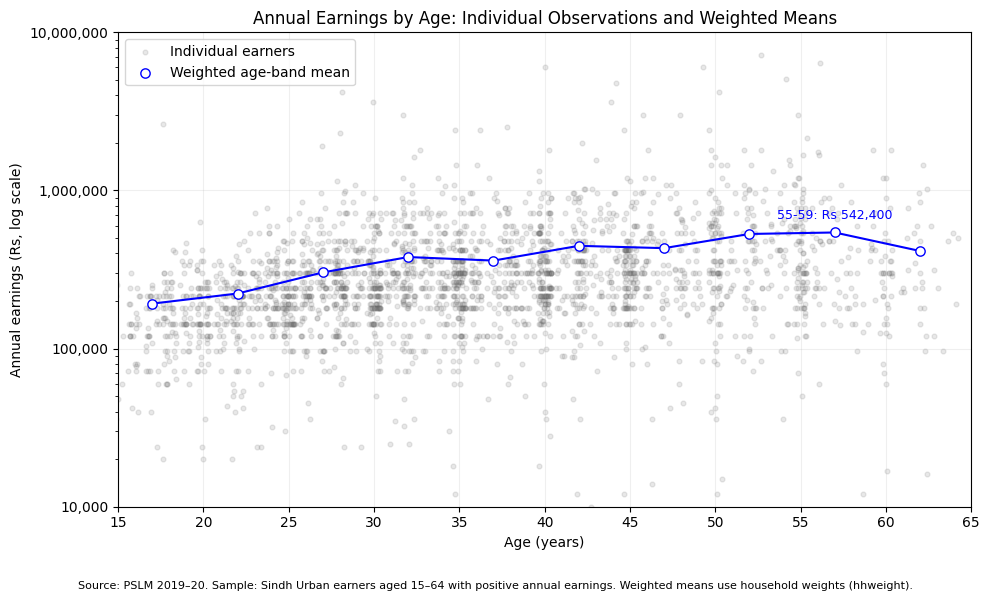

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))

# Individual earners with horizontal jitter
rng = np.random.default_rng(42)
jittered_age = data_py["age"] + rng.uniform(-0.4, 0.4, len(data_py))

ax.scatter(
    jittered_age,
    data_py["earn_annual"],
    alpha=0.15,
    color="dimgray",
    s=12,
    label="Individual earners"
)

# Weighted age-band means
ax.plot(
    band_table["midpoint"],
    band_table["weighted_mean"],
    color="blue",
    linewidth=1.5
)

# Hollow markers for weighted means
ax.scatter(
    band_table["midpoint"],
    band_table["weighted_mean"],
    facecolors="white",
    edgecolors="blue",
    s=45,
    zorder=3,
    label="Weighted age-band mean"
)

# Annotate only the highest mean
highest = band_table.loc[band_table["weighted_mean"].idxmax()]

ax.annotate(
    f'{highest["age_band"]}: Rs {highest["weighted_mean"]:,.0f}',
    (highest["midpoint"], highest["weighted_mean"]),
    xytext=(0, 10),
    textcoords="offset points",
    ha="center",
    color="blue",
    fontsize=9
)

# Match R axes
ax.set_yscale("log")
ax.set_ylim(10000, 10000000)
ax.set_xlim(15, 65)
ax.set_xticks(range(15, 66, 5))
ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

# Titles and labels
ax.set_title(
    "Annual Earnings by Age: Individual Observations and Weighted Means"
)
ax.set_xlabel("Age (years)")
ax.set_ylabel("Annual earnings (Rs, log scale)")

ax.legend()
ax.grid(alpha=0.2)
fig.text(
    0.5, 0.01,
    "Source: PSLM 2019–20. Sample: Sindh Urban earners aged 15–64 "
    "with positive annual earnings. Weighted means use household weights (hhweight).",
    ha="center",
    fontsize=8
)

fig.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()